# 🩺 Skin Disease Classification (Multi-Class) — MASTER TRAINING SCRIPT

## এই notebook-এর নিয়ম

- **শুধু `MODEL_KEY` ভ্যারিয়েবল বদলান** (Cell 3-এ) — VGG16, InceptionV3, ResNet50,
  MobileNetV2, DenseNet121, EfficientNetB0 — যেকোনো একটা লিখে বাকি সব cell
  **কোনো পরিবর্তন ছাড়াই run করুন (Run All)**।
- **কোনো augmentation নেই** — train dataset raw/অপরিবর্তিত (শুধু resize + প্রতিটা
  model-এর নিজস্ব `preprocess_input`)।
- **কোনো fine-tuning phase নেই** — ImageNet backbone সবসময় সম্পূর্ণ **frozen**
  থাকে, শুধু নতুন classification head train হয়। একটাই training phase।
- **Loss**: `CategoricalCrossentropy(label_smoothing=0.10)` — সবসময় রাখা হয়েছে
  (overconfidence/calibration সমস্যা কমায়, কোনো LR schedule-এর সাথে conflict নেই)।
- **LR strategy**: fixed initial LR + **ReduceLROnPlateau** (val_loss-ভিত্তিক
  adaptive LR drop)। **CosineDecay ব্যবহার করা হয়নি**, কারণ CosineDecay একটা
  fixed/pre-planned schedule object — `ReduceLROnPlateau` callback একটা LR
  schedule object-এর LR override করতে পারে না (schedule নিজেই LR নিয়ন্ত্রণ করে)।
  ছোট medical dataset আর single-phase (no fine-tuning) সেটআপে val_loss দেখেই
  adaptively LR কমানো বেশি নিরাপদ ও stable — তাই ReduceLROnPlateau।


In [1]:
# ⚡ ENVIRONMENT SETUP (Kaggle)
import os
import json
import pickle
import zipfile
import shutil
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix
from tqdm.auto import tqdm
from IPython.display import FileLink

print(f"✅ TensorFlow version: {tf.__version__}")
print("👉 Kaggle notebook Settings-এ 'Internet' toggle ON আছে কিনা চেক করুন — ")
print("   ImageNet pretrained weights ডাউনলোড করার জন্য এটা লাগবে।")

✅ TensorFlow version: 2.20.0
👉 Kaggle notebook Settings-এ 'Internet' toggle ON আছে কিনা চেক করুন — 
   ImageNet pretrained weights ডাউনলোড করার জন্য এটা লাগবে।


In [2]:
# =========================
# 🔒 REPRODUCIBILITY SETUP
# =========================
import random

SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("✅ Seed fixed:", SEED)

✅ Seed fixed: 42


In [3]:
# --- ১. পাথ, MODEL SELECTION ও প্যারামিটার সেটআপ ---
# ⚠️ এখানে তোমার ALREADY-SPLIT dataset-এর পাথ দাও —
# এই ফোল্ডারের ভেতরে সরাসরি train/  val/  test/  থাকতে হবে (প্রতিটার ভেতরে per-class subfolder)।
DATA_PATH = "/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2"   # <-- এখানে ঠিক পাথ বসাও

WORKING_DIR = "/kaggle/working/"
os.makedirs(WORKING_DIR, exist_ok=True)

if not os.path.exists(DATA_PATH):
    print(f"⚠️ Path not found: {DATA_PATH}")
    print("👉 আপনি কি সঠিক Kaggle dataset input যোগ করেছেন?")
else:
    print(f"✅ DATA_PATH found: {DATA_PATH}")


# =====================================================================
# ⭐⭐⭐ শুধু এই একটা লাইন বদলে different different model run করুন ⭐⭐⭐
# =====================================================================
MODEL_KEY = "EfficientNetB0"
# Options: "VGG16", "InceptionV3", "ResNet50", "MobileNetV2", "DenseNet121", "EfficientNetB0"
# =====================================================================


# ---- প্রতিটা model-এর নিজস্ব class, preprocess_input, input size, batch size ----
MODEL_REGISTRY = {
    "VGG16": dict(
        app=tf.keras.applications.VGG16,
        preprocess=tf.keras.applications.vgg16.preprocess_input,
        img_size=224, batch_per_core=32,
    ),
    "InceptionV3": dict(
        app=tf.keras.applications.InceptionV3,
        preprocess=tf.keras.applications.inception_v3.preprocess_input,
        img_size=299, batch_per_core=16,
    ),
    "ResNet50": dict(
        app=tf.keras.applications.ResNet50,
        preprocess=tf.keras.applications.resnet50.preprocess_input,
        img_size=224, batch_per_core=32,
    ),
    "MobileNetV2": dict(
        app=tf.keras.applications.MobileNetV2,
        preprocess=tf.keras.applications.mobilenet_v2.preprocess_input,
        img_size=224, batch_per_core=32,
    ),
    "DenseNet121": dict(
        app=tf.keras.applications.DenseNet121,
        preprocess=tf.keras.applications.densenet.preprocess_input,
        img_size=224, batch_per_core=32,
    ),
    "EfficientNetB0": dict(
        app=tf.keras.applications.EfficientNetB0,
        preprocess=tf.keras.applications.efficientnet.preprocess_input,
        img_size=224, batch_per_core=32,
    ),
}

if MODEL_KEY not in MODEL_REGISTRY:
    raise ValueError(f"❌ Unknown MODEL_KEY: {MODEL_KEY} — options: {list(MODEL_REGISTRY.keys())}")

MODEL_CFG        = MODEL_REGISTRY[MODEL_KEY]
ModelClass       = MODEL_CFG["app"]
PREPROCESS_FN    = MODEL_CFG["preprocess"]
IMG_DIM          = MODEL_CFG["img_size"]
BATCH_SIZE_PER_CORE = MODEL_CFG["batch_per_core"]

MODEL_NAME  = MODEL_KEY.lower()
EPOCHS_HEAD = 25   # ⭐ কোনো fine-tuning phase নেই, তাই একটাই (কম) epoch সংখ্যা

RESUME_EPOCH_PATH = os.path.join(WORKING_DIR, f"{MODEL_NAME}_resume_epoch.pkl")
BACKUP_ZIP        = os.path.join(WORKING_DIR, f"{MODEL_NAME}_resume_backup.zip")

# ⭐ ক্লাস লিস্ট train/ ফোল্ডার থেকে অটো-ডিটেক্ট হবে
_train_dir_for_classes = os.path.join(DATA_PATH, "train")
CLASS_NAMES_RAW = sorted([
    d for d in os.listdir(_train_dir_for_classes)
    if os.path.isdir(os.path.join(_train_dir_for_classes, d))
]) if os.path.exists(_train_dir_for_classes) else []

print(f"📂 মোট ক্লাস পাওয়া গেছে: {len(CLASS_NAMES_RAW)}")
for c in CLASS_NAMES_RAW:
    n = len(os.listdir(os.path.join(_train_dir_for_classes, c)))
    print(f"  📁 {c}: {n} images (train)")

config = {
    "img_dim": IMG_DIM,
    "nb_channels": 3,
    "nb_classes": len(CLASS_NAMES_RAW),
    "nb_train_data": None,   # ⚠️ পরের (verify) cell চলার পর অটো-আপডেট হবে
    "labels": CLASS_NAMES_RAW
}

LABELS     = config['labels']
NB_CLASSES = config['nb_classes']

MODEL_DIR = os.path.join(WORKING_DIR, "models", MODEL_NAME)
os.makedirs(MODEL_DIR, exist_ok=True)
WEIGHT_PATH = os.path.join(MODEL_DIR, f"{MODEL_NAME}.weights.h5")

print(f"\n✅ Selected model: {MODEL_KEY}  (input size {IMG_DIM}x{IMG_DIM})")
print(f"✅ MODEL_DIR: {MODEL_DIR}")
print(f"✅ BATCH_SIZE_PER_CORE: {BATCH_SIZE_PER_CORE}")
print(f"✅ NB_CLASSES: {NB_CLASSES}")

✅ DATA_PATH found: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2
📂 মোট ক্লাস পাওয়া গেছে: 15
  📁 Acne: 400 images (train)
  📁 Atopic Dermatitis: 400 images (train)
  📁 Contact Dermatitis: 400 images (train)
  📁 Eczema: 400 images (train)
  📁 Fungal Infection: 400 images (train)
  📁 Healthy Skin: 400 images (train)
  📁 Nail Fungal: 400 images (train)
  📁 Psoriasis: 400 images (train)
  📁 Scabies: 402 images (train)
  📁 Tinea Corporis: 400 images (train)
  📁 Tinea Cruris: 400 images (train)
  📁 Tinea Faciei: 403 images (train)
  📁 Tinea Versicolor: 400 images (train)
  📁 Urticaria: 400 images (train)
  📁 Vitiligo: 400 images (train)

✅ Selected model: EfficientNetB0  (input size 224x224)
✅ MODEL_DIR: /kaggle/working/models/efficientnetb0
✅ BATCH_SIZE_PER_CORE: 32
✅ NB_CLASSES: 15


In [4]:
# =========================
# ✅ DATASET ALREADY SPLIT — শুধু VERIFY করা হচ্ছে (কোনো নতুন split/copy হবে না)
# =========================
GCS_PATH = DATA_PATH   # ⚠️ downstream-এর সব কোড এখন থেকে এই GCS_PATH-ই ব্যবহার করবে

required_splits = ["train", "val", "test"]
missing = [s for s in required_splits if not os.path.exists(os.path.join(GCS_PATH, s))]
if missing:
    raise FileNotFoundError(
        f"❌ এই ফোল্ডার(গুলো) পাওয়া যায়নি: {missing} — DATA_PATH ঠিক আছে কিনা চেক করুন।"
    )

print("✅ train/ val/ test/ — তিনটাই পাওয়া গেছে, আলাদা করে split করার দরকার নেই।\n")

nb_train_total = 0
for split in required_splits:
    split_path = os.path.join(GCS_PATH, split)
    class_dirs = [d for d in os.listdir(split_path) if os.path.isdir(os.path.join(split_path, d))]
    n = sum(len(os.listdir(os.path.join(split_path, d))) for d in class_dirs)
    print(f"  📁 {split}: {n} images, {len(class_dirs)} classes  ({split_path})")
    if split == "train":
        nb_train_total = n

config["nb_train_data"] = nb_train_total
NB_TRAIN = nb_train_total
print(f"\n✅ NB_TRAIN (config অটো-আপডেট হলো): {NB_TRAIN}")

✅ train/ val/ test/ — তিনটাই পাওয়া গেছে, আলাদা করে split করার দরকার নেই।

  📁 train: 6005 images, 15 classes  (/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/train)
  📁 val: 752 images, 15 classes  (/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/val)
  📁 test: 750 images, 15 classes  (/kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/test)

✅ NB_TRAIN (config অটো-আপডেট হলো): 6005


In [5]:
# TPU/GPU Strategy Setup
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
    tf.config.experimental_connect_to_cluster(tpu)
    tf.tpu.experimental.initialize_tpu_system(tpu)
    strategy = tf.distribute.TPUStrategy(tpu)
    print('🟢 Running on TPU:', tpu.master())
except ValueError:
    strategy = tf.distribute.get_strategy()
    print('🟡 Running on CPU/GPU')

gpus = tf.config.list_physical_devices('GPU')
print("🖥️ Visible GPUs:", gpus)
print("REPLICAS:", strategy.num_replicas_in_sync)

BATCH_SIZE = BATCH_SIZE_PER_CORE * strategy.num_replicas_in_sync
STEPS_PER_EPOCH = max(1, NB_TRAIN // BATCH_SIZE)   # শুধু train (repeat()) dataset-এর জন্য

print(f"✅ BATCH_SIZE: {BATCH_SIZE}")
print(f"✅ STEPS_PER_EPOCH: {STEPS_PER_EPOCH}")
print("ℹ️ val/test-এর জন্য fixed 'steps' ব্যবহার করা হচ্ছে না — পুরো dataset প্রতিবার")
print("   সম্পূর্ণ evaluate হবে।")

🟡 Running on CPU/GPU
🖥️ Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
REPLICAS: 1
✅ BATCH_SIZE: 32
✅ STEPS_PER_EPOCH: 187
ℹ️ val/test-এর জন্য fixed 'steps' ব্যবহার করা হচ্ছে না — পুরো dataset প্রতিবার
   সম্পূর্ণ evaluate হবে।


In [6]:
# Medical-Safe Data Pipeline — train / val / test সম্পূর্ণ আলাদা
# ⭐ কোনো augmentation নেই — train/val/test তিনটাই শুধু resize + এই model-এর
#   নিজস্ব preprocess_input দিয়ে প্রসেস হয়, আর কিছু না।
def data_input_fn(mode):
    """mode: 'train' | 'val' | 'test'"""
    folder_path = os.path.join(GCS_PATH, mode)
    print(f"🔄 Loading {mode} from: {folder_path}")

    if not os.path.exists(folder_path):
        raise FileNotFoundError(f"Folder not found: {folder_path}")

    raw_dataset = tf.keras.utils.image_dataset_from_directory(
        folder_path,
        labels='inferred',
        label_mode='categorical',
        batch_size=None,
        image_size=(IMG_DIM, IMG_DIM),
        shuffle=False,
        seed=SEED
    )

    n_samples = tf.data.experimental.cardinality(raw_dataset).numpy()

    def preprocess(image, label):
        image = PREPROCESS_FN(image)   # ⭐ প্রতিটা model-এর নিজস্ব preprocess_input
        return image, label

    dataset = raw_dataset.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.cache()

    if mode == "train":
        dataset = dataset.shuffle(buffer_size=max(int(n_samples), 1), seed=SEED,
                                   reshuffle_each_iteration=True)

    dataset = dataset.batch(BATCH_SIZE)

    if mode == "train":
        dataset = dataset.repeat()   # ⚠️ শুধু train infinite — val/test কখনো repeat হয় না (augmentation নেই)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

print("\n" + "="*50)
print(f"📂 LOADING DATASETS (train / val / test — {MODEL_KEY}, no augmentation)")
print("="*50)

train_ds = data_input_fn("train")   # শুধু training
eval_ds  = data_input_fn("val")     # শুধু training-time monitoring + analysis
test_ds  = data_input_fn("test")    # ⭐ শুধু চূড়ান্ত, unbiased final report/confusion-matrix
print("✅ train_ds, eval_ds (val), test_ds — সব READY!")


📂 LOADING DATASETS (train / val / test — EfficientNetB0, no augmentation)
🔄 Loading train from: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/train
Found 6005 files belonging to 15 classes.


I0000 00:00:1785801192.842753      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1785801192.845738      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


🔄 Loading val from: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/val
Found 752 files belonging to 15 classes.
🔄 Loading test from: /kaggle/input/datasets/maruffalkon/augmentation-ethical-data-finetuned-last-2/Augmentation Ethical Data Finetuned Last 2/test
Found 750 files belonging to 15 classes.
✅ train_ds, eval_ds (val), test_ds — সব READY!


In [7]:
# Class Weight Calculation for Balanced Training (শুধু TRAIN ফোল্ডার থেকে)
print("\n" + "="*50)
print("⚖️ CALCULATING CLASS WEIGHTS")
print("="*50)

train_dir = os.path.join(GCS_PATH, 'train')
class_folders = sorted([f for f in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, f))])

y_train_list = []
for i, folder in enumerate(class_folders):
    folder_path = os.path.join(train_dir, folder)
    count = len(os.listdir(folder_path))
    y_train_list.extend([i] * count)
    print(f"  {folder}: {count} images")

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_list),
    y=y_train_list
)
class_weights = dict(enumerate(weights))
print("✅ Class Weights:", class_weights)


⚖️ CALCULATING CLASS WEIGHTS
  Acne: 400 images
  Atopic Dermatitis: 400 images
  Contact Dermatitis: 400 images
  Eczema: 400 images
  Fungal Infection: 400 images
  Healthy Skin: 400 images
  Nail Fungal: 400 images
  Psoriasis: 400 images
  Scabies: 402 images
  Tinea Corporis: 400 images
  Tinea Cruris: 400 images
  Tinea Faciei: 403 images
  Tinea Versicolor: 400 images
  Urticaria: 400 images
  Vitiligo: 400 images
✅ Class Weights: {0: np.float64(1.0008333333333332), 1: np.float64(1.0008333333333332), 2: np.float64(1.0008333333333332), 3: np.float64(1.0008333333333332), 4: np.float64(1.0008333333333332), 5: np.float64(1.0008333333333332), 6: np.float64(1.0008333333333332), 7: np.float64(1.0008333333333332), 8: np.float64(0.9958540630182421), 9: np.float64(1.0008333333333332), 10: np.float64(1.0008333333333332), 11: np.float64(0.9933829611248967), 12: np.float64(1.0008333333333332), 13: np.float64(1.0008333333333332), 14: np.float64(1.0008333333333332)}


In [8]:
# --- Learning Rate & Callbacks (Single-Phase, No Fine-Tuning) ---

class SaveEpochCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        with open(RESUME_EPOCH_PATH, 'wb') as f:
            pickle.dump(epoch + 1, f)

# ⭐ কোনো fine-tuning phase নেই, তাই একটাই LR strategy: FIXED initial LR +
#   ReduceLROnPlateau (CosineDecay ব্যবহার করা হয়নি, কারণ schedule object আর
#   ReduceLROnPlateau একসাথে কাজ করে না — schedule নিজেই LR নিয়ন্ত্রণ করে,
#   callback সেটা override করতে পারে না)।
INITIAL_LR = 1e-4

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,        # প্রতিবার LR অর্ধেক হয়ে যাবে
    patience=2,         # ২ epoch ধরে val_loss উন্নতি না হলে LR কমবে
    min_lr=1e-7,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    verbose=1,
    restore_best_weights=True
)

model_autosave = tf.keras.callbacks.ModelCheckpoint(
    WEIGHT_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1,
    save_weights_only=True
)

callbacks_list = [model_autosave, reduce_lr, early_stopping, SaveEpochCallback()]

print("✅ Callbacks ready: ModelCheckpoint + ReduceLROnPlateau + fast EarlyStopping (patience=4)")

✅ Callbacks ready: ModelCheckpoint + ReduceLROnPlateau + fast EarlyStopping (patience=4)


In [9]:
print("\n" + "="*50)
print(f"🏗️ BUILDING {MODEL_KEY} MODEL (single-phase, no fine-tuning)")
print("="*50)

USE_XLA = True
USE_MIXED_PRECISION = True
if USE_MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
    print("✅ Mixed precision (mixed_float16) enabled")

with strategy.scope():
    base_model = ModelClass(
        input_shape=(IMG_DIM, IMG_DIM, 3),
        include_top=False,
        weights='imagenet'
    )
    base_model.trainable = False  # ⭐ ImageNet backbone সম্পূর্ণ FROZEN — কখনো unfreeze হয় না (no fine-tuning)।
                                   #   শুধু নতুন head (GAP/GMP/Dense/BN/Dropout) train হয়।

    inputs = base_model.input
    x = base_model.output
    x_avg = tf.keras.layers.GlobalAveragePooling2D()(x)
    x_max = tf.keras.layers.GlobalMaxPooling2D()(x)
    x = tf.keras.layers.Concatenate()([x_avg, x_max])
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    x = tf.keras.layers.Dense(
        256, activation='swish',
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(NB_CLASSES, activation="softmax", dtype='float32')(x)

    model = tf.keras.Model(inputs=inputs, outputs=outputs)

    model.compile(
        # ⭐ INITIAL_LR (fixed, schedule না) — ReduceLROnPlateau এটা runtime-এ কমাবে।
        optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR, clipnorm=1.0),
        loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.10),
        metrics=['accuracy', tf.keras.metrics.Recall(name='recall')],
        jit_compile=USE_XLA
    )

model.summary()


🏗️ BUILDING EfficientNetB0 MODEL (single-phase, no fine-tuning)
✅ Mixed precision (mixed_float16) enabled
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/trainer.py:212: UserWarning: Model doesn't support `jit_compile=True`. Proceeding with `jit_compile=False`.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,720,306 (18.01 MB)

 Trainable params: 665,103 (2.54 MB)

 Non-trainable params: 4,055,203 (15.47 MB)

In [10]:
# Training (single-phase — backbone FROZEN throughout, কোনো fine-tuning নেই)
print("\n" + "="*50)
print(f"🚀 TRAINING — backbone FROZEN ({MODEL_KEY}), no fine-tuning phase")
print("="*50)

initial_epoch = 0

if os.path.exists(WEIGHT_PATH):
    print("🔁 Resuming previous training...")
    model.load_weights(WEIGHT_PATH)

    if os.path.exists(RESUME_EPOCH_PATH):
        with open(RESUME_EPOCH_PATH, 'rb') as f:
            initial_epoch = pickle.load(f)

    print(f"✅ Starting from epoch {initial_epoch}")

history = model.fit(
    train_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    epochs=EPOCHS_HEAD,
    initial_epoch=initial_epoch,
    validation_data=eval_ds,      # ⭐ VAL — কোনো validation_steps নেই, পুরো val set প্রতি epoch-এ ব্যবহার হবে
    callbacks=callbacks_list,
    class_weight=class_weights
)


🚀 TRAINING — backbone FROZEN (EfficientNetB0), no fine-tuning phase
Epoch 1/25
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2716 - loss: 2.8209 - recall: 0.1506
Epoch 1: val_accuracy improved from None to 0.60638, saving model to /kaggle/working/models/efficientnetb0/efficientnetb0.weights.h5

Epoch 1: finished saving model to /kaggle/working/models/efficientnetb0/efficientnetb0.weights.h5
187/187 ━━━━━━━━━━━━━━━━━━━━ 63s 148ms/step - accuracy: 0.4226 - loss: 2.2693 - recall: 0.2836 - val_accuracy: 0.6064 - val_loss: 1.6275 - val_recall: 0.2779 - learning_rate: 1.0000e-04
Epoch 2/25
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6873 - loss: 1.4784 - recall: 0.5455
Epoch 2: val_accuracy improved from 0.60638 to 0.74601, saving model to /kaggle/working/models/efficientnetb0/efficientnetb0.weights.h5

Epoch 2: finished saving model to /kaggle/working/models/efficientnetb0/efficientnetb0.weights.h5
187/187 ━━━━━━━━━━━━━━━━━━━━ 24s 80ms/step - accuracy: 0.7259 - loss: 

## 📊 Training Analysis (VALIDATION SET)

Training শেষ হওয়ার পর, সেভ হওয়া সেরা checkpoint দিয়ে VAL সেটের উপর
classification report + confusion matrix। যেহেতু কোনো fine-tuning phase নেই,
এটাই একমাত্র/চূড়ান্ত analysis (নিচের "Final Result" cell-এও একই weights আবার
লোড করে TEST সেটে যাচাই করা হবে)।


📊 TRAINING ANALYSIS (EfficientNetB0, single-phase, no fine-tuning) — TEST SET
24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 433ms/step - accuracy: 0.9333 - loss: 0.8400 - recall: 0.8520
✅ Test Accuracy: 93.33%
✅ Test Recall:   85.20%
⏳ Processing Predictions (TEST)...


  0%|          | 0/24 [00:00<?, ?it/s]

2026-08-04 00:00:42.213296: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}



📋 FINAL CLASSIFICATION REPORT (TEST SET, n=750)
                   precision  recall f1-score support
Acne                  0.7812  1.0000   0.8772      50
Atopic Dermatitis     0.9286  0.7800   0.8478      50
Contact Dermatitis    1.0000  0.9800   0.9899      50
Eczema                0.9583  0.9200   0.9388      50
Fungal Infection      1.0000  0.9800   0.9899      50
Healthy Skin          0.9245  0.9800   0.9515      50
Nail Fungal           1.0000  1.0000   1.0000      50
Psoriasis             0.9259  1.0000   0.9615      50
Scabies               0.9348  0.8600   0.8958      50
Tinea Corporis        0.9706  0.6600   0.7857      50
Tinea Cruris          0.8772  1.0000   0.9346      50
Tinea Faciei          1.0000  1.0000   1.0000      50
Tinea Versicolor      1.0000  0.9400   0.9691      50
Urticaria             1.0000  0.9000   0.9474      50
Vitiligo              0.8065  1.0000   0.8929      50
accuracy                               0.9333     750
macro avg             0.9405  0.9

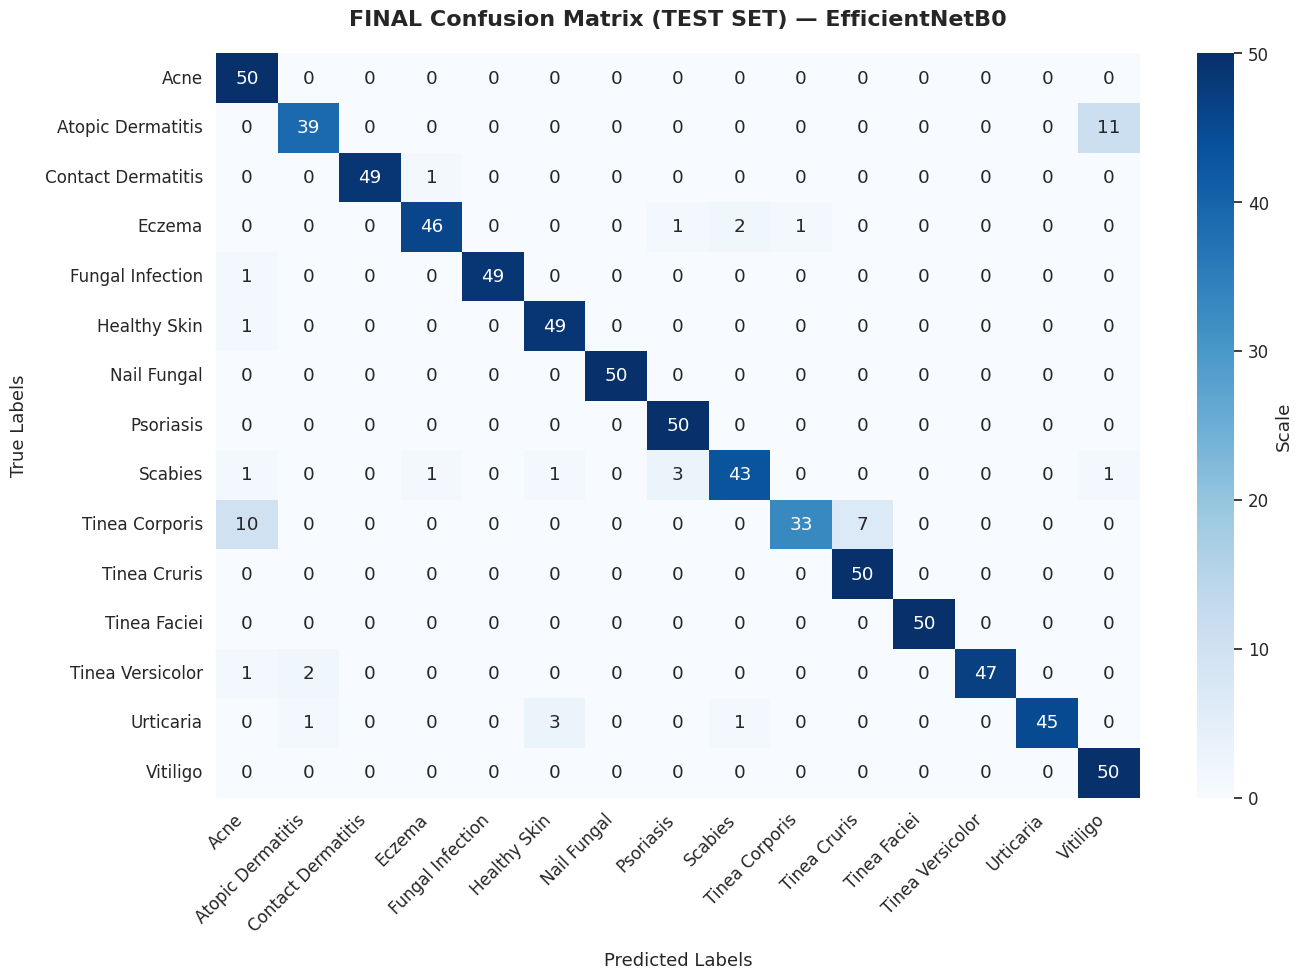

array([[50,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0, 39,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 11],
       [ 0,  0, 49,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 46,  0,  0,  0,  1,  2,  1,  0,  0,  0,  0,  0],
       [ 1,  0,  0,  0, 49,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 1,  0,  0,  0,  0, 49,  0,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 50,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 50,  0,  0,  0,  0,  0,  0,  0],
       [ 1,  0,  0,  1,  0,  1,  0,  3, 43,  0,  0,  0,  0,  0,  1],
       [10,  0,  0,  0,  0,  0,  0,  0,  0, 33,  7,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 50,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 50,  0,  0,  0],
       [ 1,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 47,  0,  0],
       [ 0,  1,  0,  0,  0,  3,  0,  0,  1,  0,  0,  0,  0, 45,  0],
       [ 0,  0,  0,  0,  0,  0,  0

In [11]:
# --- Training Analysis — TEST SET ---
print("\n" + "="*50)
print(f"📊 TRAINING ANALYSIS ({MODEL_KEY}, single-phase, no fine-tuning) — TEST SET")
print("="*50)

model.load_weights(WEIGHT_PATH)   # training-এর সেরা checkpoint
p1_test_loss, p1_test_acc, p1_test_recall = model.evaluate(test_ds)
print(f"✅ Test Accuracy: {p1_test_acc*100:.2f}%")
print(f"✅ Test Recall:   {p1_test_recall*100:.2f}%")

def get_predictions(dataset):
    gts, preds = [], []
    for x, y in tqdm(dataset):
        y_pred = model.predict(x, verbose=0)
        gts.extend(np.argmax(y, axis=1))
        preds.extend(np.argmax(y_pred, axis=1))
    return np.array(gts), np.array(preds)

def plot_confusion(gts, preds, class_names, title, save_path=None):
    con_mat = confusion_matrix(gts, preds)
    df_cm = pd.DataFrame(con_mat, index=class_names, columns=class_names)
    plt.figure(figsize=(14, 10))
    sn.set_theme(style="white")
    sn.set(font_scale=1.1)
    sn.heatmap(df_cm, annot=True, fmt='g', cmap='Blues',
               xticklabels=class_names, yticklabels=class_names,
               cbar_kws={'label': 'Scale'})
    plt.title(title, fontsize=16, pad=20, fontweight='bold')
    plt.xlabel("Predicted Labels", fontsize=13, labelpad=12)
    plt.ylabel("True Labels", fontsize=13, labelpad=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    return con_mat

def print_formatted_report(gts, preds, class_names, title):
    """Print classification report as a 4-decimal formatted table (image style)."""
    report_dict = classification_report(gts, preds, target_names=class_names, output_dict=True)

    # 'accuracy' comes back as a plain float in output_dict -> reshape it so it
    # matches the image style: blank precision/recall, f1-score = accuracy, support = total n
    total_support = int(report_dict["macro avg"]["support"])
    acc_value = report_dict["accuracy"]
    report_dict["accuracy"] = {
        "precision": None,
        "recall": None,
        "f1-score": acc_value,
        "support": total_support,
    }

    report_df = pd.DataFrame(report_dict).transpose()

    disp = pd.DataFrame(index=report_df.index, columns=["precision", "recall", "f1-score", "support"])
    for col in ["precision", "recall", "f1-score"]:
        disp[col] = report_df[col].apply(lambda x: "" if pd.isna(x) else f"{x:.4f}")
    disp["support"] = report_df["support"].apply(lambda x: "" if pd.isna(x) else f"{int(x)}")

    print("\n" + "="*50)
    print(title)
    print("="*50)
    print(disp.to_string())
    return report_dict

test_dir = os.path.join(GCS_PATH, 'test')
class_names_test = sorted(os.listdir(test_dir))

print("⏳ Processing Predictions (TEST)...")
p1_gts, p1_preds = get_predictions(test_ds)

print_formatted_report(
    p1_gts, p1_preds, class_names_test,
    f"📋 FINAL CLASSIFICATION REPORT (TEST SET, n={len(p1_gts)})"
)

plot_confusion(p1_gts, p1_preds, class_names_test,
               f"FINAL Confusion Matrix (TEST SET) — {MODEL_KEY}",
               os.path.join(MODEL_DIR, "test_confusion_matrix.png"))

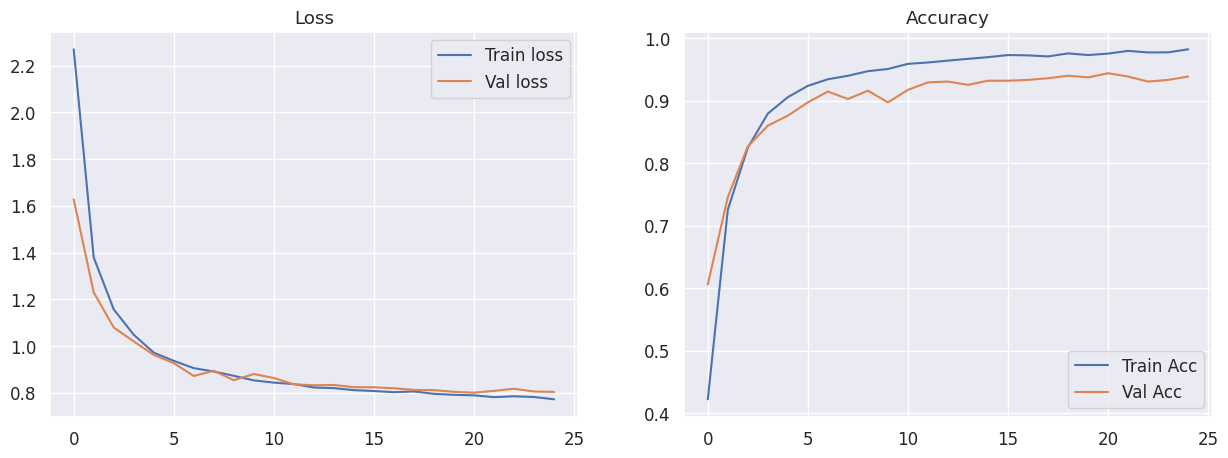

In [12]:
# Plot Training Metrics
def plot_history(history, MODEL_DIR, iden):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(15, 5))
    ax_loss.plot(history.epoch, history.history["loss"], label="Train loss")
    ax_loss.plot(history.epoch, history.history["val_loss"], label="Val loss")
    ax_loss.set_title("Loss")
    ax_loss.legend()
    ax_acc.plot(history.epoch, history.history["accuracy"], label="Train Acc")
    ax_acc.plot(history.epoch, history.history["val_accuracy"], label="Val Acc")
    ax_acc.set_title("Accuracy")
    ax_acc.legend()
    plt.savefig(os.path.join(MODEL_DIR, f"{iden}_metrics.png"), dpi=150)
    plt.show()

plot_history(history, MODEL_DIR, f"{MODEL_NAME}_training")

## 🏁 Final Result — VALIDATION vs TEST

Training-এর সেরা checkpoint দিয়ে VAL (monitoring metric) আর **TEST**
(চূড়ান্ত, unbiased metric — কখনো training/model-selection-এ touch হয়নি) —
দুটোর accuracy/recall পাশাপাশি দেখানো হচ্ছে।

In [13]:
# Load Best (Final) Weights
print("\n" + "="*50)
print("📥 LOADING BEST WEIGHTS (final checkpoint)")
print("="*50)
model.load_weights(WEIGHT_PATH)
print("✅ Best weights loaded")

# --- VALIDATION metrics ---
print("\n" + "="*50)
print("📊 VALIDATION SET — FINAL")
print("="*50)
val_loss, val_acc, val_recall = model.evaluate(eval_ds)
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Validation Recall:   {val_recall*100:.2f}%")

# --- TEST metrics (⭐ চূড়ান্ত, unbiased) ---
print("\n" + "="*50)
print(f"📊 TEST SET — FINAL ({MODEL_KEY}) — ⭐ thesis/report-এ এটাই ব্যবহার করুন")
print("="*50)
test_loss, test_acc, test_recall = model.evaluate(test_ds)
print(f"✅ Final TEST Accuracy: {test_acc*100:.2f}%")
print(f"✅ Final TEST Recall:   {test_recall*100:.2f}%")

print("\n" + "="*50)
print("📈 SUMMARY TABLE")
print("="*50)
summary_df = pd.DataFrame({
    "Model": [MODEL_KEY]*3,
    "Stage": ["Training - VAL", "Final - VAL", "Final - TEST"],
    "Accuracy (%)": [p1_val_acc*100, val_acc*100, test_acc*100],
    "Recall (%)":   [p1_val_recall*100, val_recall*100, test_recall*100],
})
print(summary_df.to_string(index=False))
summary_df.to_csv(os.path.join(MODEL_DIR, "accuracy_summary.csv"), index=False)


📥 LOADING BEST WEIGHTS (final checkpoint)
✅ Best weights loaded

📊 VALIDATION SET — FINAL
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.9441 - loss: 0.8007 - recall: 0.8803
Validation Accuracy: 94.41%
Validation Recall:   88.03%

📊 TEST SET — FINAL (EfficientNetB0) — ⭐ thesis/report-এ এটাই ব্যবহার করুন
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 0.9333 - loss: 0.8400 - recall: 0.8520
✅ Final TEST Accuracy: 93.33%
✅ Final TEST Recall:   85.20%

📈 SUMMARY TABLE


NameError: name 'p1_val_acc' is not defined

## 🎯 Final Master Evaluation — TEST SET (Classification Report + Confusion Matrix)

এইটাই চূড়ান্ত, সবাই যেটা করে থাকে — পুরো TEST সেটের উপর একটাই সম্পূর্ণ
classification report ও confusion matrix।

In [ ]:
# Final Master Evaluation — ⭐ TEST SET
test_dir = os.path.join(GCS_PATH, 'test')
class_names = sorted(os.listdir(test_dir)) if os.path.exists(test_dir) else LABELS
print(f"✅ Class Names: {class_names}")

print("⏳ Processing Predictions on TEST set...")
gts, preds = get_predictions(test_ds)

print("\n" + "="*50)
print(f"📋 FINAL CLASSIFICATION REPORT ({MODEL_KEY}, TEST SET, n={len(gts)})")
print("="*50)
report = classification_report(gts, preds, target_names=class_names)
print(report)

with open(os.path.join(MODEL_DIR, "final_test_classification_report.txt"), "w") as f:
    f.write(report)

con_mat = plot_confusion(gts, preds, class_names,
                          f"FINAL Confusion Matrix (TEST SET) - {MODEL_KEY}",
                          os.path.join(MODEL_DIR, "confusion_matrix.png"))

## ❌ Misclassified Analysis — কোন ক্লাসে সবচেয়ে বেশি সমস্যা (TEST SET)

- একটা bar গ্রাফ, যেখানে প্রতিটা class-এ কতগুলো ছবি ভুল classify হয়েছে (count)
  এবং error rate (%) দেখানো হয়েছে, সবচেয়ে বেশি সমস্যাযুক্ত ক্লাস উপরে।
- ভুল classify হওয়া প্রতিটা ছবি `misclassified_test/true_X_pred_Y/` ফোল্ডারে
  সেভ হবে, যাতে ছবিগুলো সরাসরি চোখে দেখা যায়।

In [ ]:
# ==============================
# ❌ MISCLASSIFIED IMAGES + PER-CLASS ERROR ANALYSIS — TEST SET
# ==============================

MISCLASS_DIR = os.path.join(WORKING_DIR, f"{MODEL_NAME}_misclassified_test")
os.makedirs(MISCLASS_DIR, exist_ok=True)

class_names_dir = sorted(os.listdir(test_dir))
print("📂 Classes:", class_names_dir)

total_per_class = {c: 0 for c in class_names_dir}
wrong_per_class = {c: 0 for c in class_names_dir}
count = 0

for class_idx, class_name in enumerate(class_names_dir):
    class_path = os.path.join(test_dir, class_name)

    for img_name in os.listdir(class_path):
        img_path = os.path.join(class_path, img_name)

        try:
            img = tf.keras.utils.load_img(img_path, target_size=(IMG_DIM, IMG_DIM))
            img_array = tf.keras.utils.img_to_array(img)
            img_array = tf.expand_dims(img_array, axis=0)
            img_array = PREPROCESS_FN(img_array)   # ⭐ এই model-এর নিজস্ব preprocess_input

            pred = model.predict(img_array, verbose=0)
            pred_class = np.argmax(pred)
            true_class = class_idx

            total_per_class[class_name] += 1

            if pred_class != true_class:
                wrong_per_class[class_name] += 1
                save_folder = os.path.join(
                    MISCLASS_DIR,
                    f"true_{class_names_dir[true_class]}_pred_{class_names_dir[pred_class]}"
                )
                os.makedirs(save_folder, exist_ok=True)
                shutil.copy(img_path, os.path.join(save_folder, img_name))
                count += 1

        except Exception as e:
            print("Error:", e)

print(f"❌ Total Misclassified Images Saved: {count}")
print(f"📁 Location: {MISCLASS_DIR}")

# --- Per-class error summary ---
error_df = pd.DataFrame({
    "Class": list(total_per_class.keys()),
    "Total": list(total_per_class.values()),
    "Misclassified": [wrong_per_class[c] for c in total_per_class],
})
error_df["Error Rate (%)"] = (error_df["Misclassified"] / error_df["Total"] * 100).round(2)
error_df = error_df.sort_values("Error Rate (%)", ascending=False).reset_index(drop=True)

print("\n" + "="*50)
print("📋 PER-CLASS ERROR SUMMARY (sorted — সবচেয়ে বেশি সমস্যা উপরে)")
print("="*50)
print(error_df.to_string(index=False))
error_df.to_csv(os.path.join(MODEL_DIR, "per_class_error_summary.csv"), index=False)

# --- Bar graph ---
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sn.barplot(data=error_df, y="Class", x="Misclassified", ax=axes[0], color="#e74c3c")
axes[0].set_title(f"Misclassified Image Count per Class ({MODEL_KEY}, TEST)", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Number of Misclassified Images")
axes[0].set_ylabel("")

sn.barplot(data=error_df, y="Class", x="Error Rate (%)", ax=axes[1], color="#e67e22")
axes[1].set_title(f"Error Rate (%) per Class ({MODEL_KEY}, TEST)", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Error Rate (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, "per_class_error_analysis.png"), dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
# Save Full Model
model.save(f'{MODEL_NAME}_skin_model.keras')
with zipfile.ZipFile(BACKUP_ZIP, 'w') as zipf:
    if os.path.exists(WEIGHT_PATH):
        zipf.write(WEIGHT_PATH, arcname="weights.h5")
    if os.path.exists(RESUME_EPOCH_PATH):
        zipf.write(RESUME_EPOCH_PATH, arcname="resume_epoch.pkl")

print("✅ Resume backup created")
display(FileLink(BACKUP_ZIP))
print(f"✅ Model saved as {MODEL_NAME}_skin_model.keras")

FileLink(WEIGHT_PATH)

results_zip = f"{MODEL_NAME}_results.zip"
with zipfile.ZipFile(results_zip, 'w') as zipf:
    zipf.write(os.path.join(MODEL_DIR, "confusion_matrix.png"))
    if os.path.exists(WEIGHT_PATH):
        zipf.write(WEIGHT_PATH)
    zipf.write(os.path.join(MODEL_DIR, "per_class_error_analysis.png"))
    zipf.write(os.path.join(MODEL_DIR, "accuracy_summary.csv"))
    zipf.write(os.path.join(MODEL_DIR, "per_class_error_summary.csv"))

display(FileLink(results_zip))

In [ ]:
# ==============================
# 📦 ZIP MISCLASSIFIED FOLDER (TEST SET)
# ==============================

zip_path = shutil.make_archive(
    base_name=MISCLASS_DIR,
    format='zip',
    root_dir=MISCLASS_DIR
)

print("✅ ZIP Created:", zip_path)